# Normative Model (Structural + Site, balanced split)

Train a quantile regression MLP that predicts the 10th, 50th and 90th percentiles of the total gray matter volume (`TotalGrayVol`) given Age, Sex and acquisition Site.

The train/validation/test split is balanced by site (each site is split 70/15/15).

Input data: `../data/processed/abide_structural_site_cleaned.csv` (from `preprocessing_structural_site.ipynb`)

In [1]:
# Import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, Subset
import os
import json
import random
import copy

In [2]:
# Random seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device: GPU (cuda), Apple Silicon (mps) or cpu
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Device: {device}")
print(f"PyTorch version: {torch.__version__}")

Device: mps
PyTorch version: 2.5.1


## Load Data

Loading the preprocessed dataset and the scaling parameters (used later to transform predictions back to mm³).

In [3]:
# Preprocessed dataset
df = pd.read_csv("../data/processed/abide_structural_site_cleaned.csv")
print(f"Total samples: {len(df)}")

# Scaling parameters
with open("../data/processed/scaling_params_structural_site.json", "r") as f:
    scaling_params = json.load(f)

age_mean = scaling_params['age_mean']
age_std = scaling_params['age_std']
vol_mean = scaling_params['vol_mean']
vol_std = scaling_params['vol_std']
print(scaling_params)

df.head()

Total samples: 477
{'age_mean': 16.95909895178197, 'age_std': 7.32014240993593, 'vol_mean': 726986.6218631573, 'vol_std': 77565.06628857981}


,FILE_ID,SITE_ID,AGE_AT_SCAN,SEX,TotalGrayVol,IntraCranialVol,Left-Hippocampus,Right-Hippocampus,Hippocampus,site_CALTECH,...,site_STANFORD,site_TRINITY,site_UCLA_1,site_UCLA_2,site_UM_1,site_UM_2,site_USM,site_YALE,Age_scaled,TotalGrayVol_scaled
0,Pitt_0050030,PITT,25.12,0,706581.114475,1.157527e+06,3982.0,4061.0,8043.0,0,...,0,0,0,0,0,0,0,0,1.114856,-0.263076
1,Pitt_0050031,PITT,12.92,0,783889.187268,1.208583e+06,4235.0,4477.0,8712.0,0,...,0,0,0,0,0,0,0,0,-0.551779,0.733611
2,Pitt_0050032,PITT,19.80,0,730058.146235,1.206391e+06,4475.0,4598.0,9073.0,0,...,0,0,0,0,0,0,0,0,0.388094,0.039599
3,Pitt_0050033,PITT,12.15,0,720818.859215,1.059904e+06,4445.0,4379.0,8824.0,0,...,0,0,0,0,0,0,0,0,-0.656968,-0.079517
4,Pitt_0050034,PITT,14.77,0,729693.739442,1.094946e+06,4074.0,4394.0,8468.0,0,...,0,0,0,0,0,0,0,0,-0.299051,0.034901


**Dataset and DataLoader**

Converting the inputs (`Age_scaled`, `SEX` and the site columns `site_...`) and target (`TotalGrayVol_scaled`) into a PyTorch `TensorDataset`, and splitting the data into training (70%), validation (15%) and testing (15%) sets.

The split is done within each site, so the three sets have the same mix of sites.

In [4]:
# Site columns
site_cols = [col for col in df.columns if col.startswith('site_')]
print(f"Number of input features: {2 + len(site_cols)} (Age, Sex + {len(site_cols)} sites)")

# Inputs and target as tensors
X = torch.tensor(df[['Age_scaled', 'SEX'] + site_cols].values, dtype=torch.float32)
y = torch.tensor(df['TotalGrayVol_scaled'].values, dtype=torch.float32).unsqueeze(1)

# call dataset
dataset = TensorDataset(X, y)

# Split data (70/15/15) within each site
rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []
for site, site_df in df.groupby('SITE_ID'):
    idx = rng.permutation(site_df.index.values)
    n_train = int(round(0.70 * len(idx)))
    n_val = int(round(0.15 * len(idx)))
    train_idx += list(idx[:n_train])
    val_idx += list(idx[n_train:n_train + n_val])
    test_idx += list(idx[n_train + n_val:])

train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)

print(f"Training set size: {len(train_dataset)} samples")
print(f"Validation set size: {len(val_dataset)} samples")
print(f"Test set size: {len(test_dataset)} samples")

# dataloaders
batch_size = 16
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

Number of input features: 22 (Age, Sex + 20 sites)
Training set size: 334 samples
Validation set size: 73 samples
Test set size: 70 samples


## Model

MLP with a shared backbone (inputs: Age, Sex and Site) and three outputs: the 10th, 50th (median) and 90th percentiles.

To avoid quantile crossing (e.g. $q_{10} > q_{50}$), the model predicts the median and two distances, made positive with `F.softplus`:

$$\hat{y}_{10} = \hat{y}_{50} - \text{Softplus}(\Delta_{10}) \qquad \hat{y}_{90} = \hat{y}_{50} + \text{Softplus}(\Delta_{90})$$

So $\hat{y}_{10} \le \hat{y}_{50} \le \hat{y}_{90}$ always.

Where:
* $\Delta_{10}$ and $\Delta_{90}$ are the raw outputs of `head_lower` and `head_upper`. They can be any number (positive or negative).
* $\text{Softplus}(x) = \log(1 + e^x)$ turns any number into a positive one (a smooth version of ReLU).

So $\text{Softplus}(\Delta_{10})$ is the distance from the median down to $q_{10}$, and $\text{Softplus}(\Delta_{90})$ the distance up to $q_{90}$.

In [5]:
class QuantileMLP(nn.Module):
    def __init__(self, in_features=2, hidden_dim=32):
        super().__init__()
        # Shared backbone
        self.backbone = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )
        # Outputs: median and the two distances
        self.head_q50 = nn.Linear(hidden_dim, 1)
        self.head_lower = nn.Linear(hidden_dim, 1)
        self.head_upper = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        features = self.backbone(x)
        q50 = self.head_q50(features)
        # softplus makes the distances positive
        q10 = q50 - F.softplus(self.head_lower(features))
        q90 = q50 + F.softplus(self.head_upper(features))
        # The output has a shape [batch_size, 3], with columns q10, q50, q90
        return torch.cat([q10, q50, q90], dim=1)

model = QuantileMLP(in_features=X.shape[1]).to(device)
print(model)
print(f"Number of parameters: {sum(p.numel() for p in model.parameters())}")

# check with the first batch from train_loader (untrained model)
batch_X, batch_y = next(iter(train_loader))
with torch.no_grad():
    preds = model(batch_X.to(device))
print(f"Output shape: {preds.shape}")
print(f"First 3 predictions [q10, q50, q90]:\n{preds[:3]}")

QuantileMLP(
  (backbone): Sequential(
    (0): Linear(in_features=22, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
  )
  (head_q50): Linear(in_features=32, out_features=1, bias=True)
  (head_lower): Linear(in_features=32, out_features=1, bias=True)
  (head_upper): Linear(in_features=32, out_features=1, bias=True)
)
Number of parameters: 1891


Output shape: torch.Size([16, 3])


First 3 predictions [q10, q50, q90]:
tensor([[-0.5570,  0.0511,  0.8532],
        [-0.5942,  0.0384,  0.8689],
        [-0.5578,  0.0451,  0.8663]], device='mps:0')


## Pinball Loss

The loss that makes each output learn its quantile. For a quantile $\tau$ (0.10, 0.50 or 0.90), with error $u = y - \hat{y}_{\tau}$:

$$L_{\tau}(u) = \max(\tau \, u, \; (\tau - 1) \, u)$$

* $q_{10}$ ($\tau = 0.10$): predicting too high costs 9 times more than too low, so it moves down until ~10% of subjects are below it.
* $q_{50}$ ($\tau = 0.50$): both errors cost the same, so it learns the median.
* $q_{90}$ ($\tau = 0.90$): predicting too low costs 9 times more, so ~90% of subjects end up below it.

The total loss is the mean over the three quantiles and all subjects.

In [6]:
def pinball_loss(preds, y, quantiles=[0.10, 0.50, 0.90]):
    """
    Mean pinball (quantile) loss over all subjects and quantiles.

    preds: model predictions, shape [batch_size, 3], with columns q10, q50, q90
    y: true TotalGrayVol values (scaled), shape [batch_size, 1]
    quantiles: quantile of each column of preds, in the same order
    Returns: the loss as a single number (tensor)
    """
    tau = torch.tensor(quantiles, device=preds.device)
    # Error of each quantile, y is broadcast to [batch_size, 3]
    u = y - preds
    loss = torch.max(tau * u, (tau - 1) * u)
    return loss.mean()

# check with the first batch from train_loader (untrained model)
with torch.no_grad():
    loss = pinball_loss(model(batch_X.to(device)), batch_y.to(device))
print(f"Loss (untrained model): {loss.item():.4f}")

Loss (untrained model): 0.2893


## Training

Each epoch:
1. **Train:** for each batch, predict, compute the pinball loss, and update the weights (`optimizer.step()`).
2. **Validate:** compute the loss on the validation set, without updating the weights.

The model with the lowest validation loss is kept as the best model.

* `AdamW` with `weight_decay`: keeps the weights small to reduce overfitting.
* `ReduceLROnPlateau`: halves the learning rate when the validation loss stops improving for 12 epochs.

In [7]:
# Training settings
epochs = 300
learning_rate = 1e-3
optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=12)

train_losses = []
val_losses = []
best_val_loss = float('inf')

for epoch in range(epochs):
    # Train
    model.train()
    train_loss = 0.0
    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()                        # reset gradients
        loss = pinball_loss(model(batch_X), batch_y)
        loss.backward()                              # compute gradients
        optimizer.step()                             # update weights
        train_loss += loss.item() * len(batch_X)
    train_losses.append(train_loss / len(train_dataset))

    # Validate
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            val_loss += pinball_loss(model(batch_X), batch_y).item() * len(batch_X)
    val_losses.append(val_loss / len(val_dataset))
    scheduler.step(val_losses[-1])                   # adjust learning rate

    # Keep the best model
    if val_losses[-1] < best_val_loss:
        best_val_loss = val_losses[-1]
        best_epoch = epoch + 1
        best_model_state = copy.deepcopy(model.state_dict())

    if (epoch + 1) % 25 == 0:
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Epoch {epoch + 1}/{epochs} | Train loss: {train_losses[-1]:.4f} | Val loss: {val_losses[-1]:.4f} | LR: {current_lr:.6f}")

# Load the best model
model.load_state_dict(best_model_state)
print(f"Best model: epoch {best_epoch}, val loss {best_val_loss:.4f}")

Epoch 25/300 | Train loss: 0.1732 | Val loss: 0.2010 | LR: 0.001000


Epoch 50/300 | Train loss: 0.1693 | Val loss: 0.2043 | LR: 0.000250


Epoch 75/300 | Train loss: 0.1683 | Val loss: 0.2057 | LR: 0.000063


Epoch 100/300 | Train loss: 0.1681 | Val loss: 0.2057 | LR: 0.000016


Epoch 125/300 | Train loss: 0.1680 | Val loss: 0.2057 | LR: 0.000004


...

Epoch 200/300 | Train loss: 0.1680 | Val loss: 0.2058 | LR: 0.000000


Epoch 225/300 | Train loss: 0.1680 | Val loss: 0.2058 | LR: 0.000000


Epoch 250/300 | Train loss: 0.1680 | Val loss: 0.2058 | LR: 0.000000


Epoch 275/300 | Train loss: 0.1680 | Val loss: 0.2058 | LR: 0.000000


Epoch 300/300 | Train loss: 0.1680 | Val loss: 0.2058 | LR: 0.000000
Best model: epoch 16, val loss 0.1974


**Baseline**

Comparing with a baseline that ignores Age and Sex: the same 10th, 50th and 90th percentiles (from the training set) for everyone. If the model learned something, its validation loss should be lower.

In [8]:
# Percentiles of the training targets
y_train = y[train_dataset.indices]
baseline_q = torch.quantile(y_train, torch.tensor([0.10, 0.50, 0.90]))

# Same prediction for every validation subject
y_val = y[val_dataset.indices]
baseline_loss = pinball_loss(baseline_q.repeat(len(y_val), 1), y_val).item()

print(f"Baseline val loss: {baseline_loss:.4f}")
print(f"Model val loss:    {best_val_loss:.4f}")
print(f"Improvement:       {100 * (baseline_loss - best_val_loss) / baseline_loss:.1f}%")

Baseline val loss: 0.2448
Model val loss:    0.1974
Improvement:       19.4%


## Loss Curves

Train and validation loss per epoch. The dashed line is the best epoch (model kept), and the dotted line the baseline.

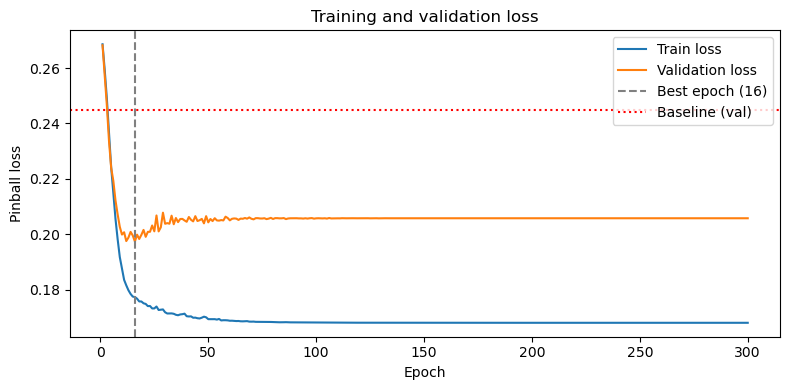

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), train_losses, label='Train loss')
plt.plot(range(1, epochs + 1), val_losses, label='Validation loss')
plt.axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch ({best_epoch})')
plt.axhline(baseline_loss, color='red', linestyle=':', label='Baseline (val)')
plt.xlabel('Epoch')
plt.ylabel('Pinball loss')
plt.title('Training and validation loss')
plt.legend()
plt.tight_layout()
plt.show()

## Test Set Calibration

Checking on the test set (not used during training) whether the quantiles are correct: about 10% of subjects should be below $q_{10}$, 50% below $q_{50}$ and 90% below $q_{90}$. Also the test loss, compared with the baseline.

In [10]:
# Predictions for the test set
y_test = y[test_dataset.indices]
model.eval()
with torch.no_grad():
    test_preds = model(X[test_dataset.indices].to(device)).cpu()

# Test loss vs baseline
test_loss = pinball_loss(test_preds, y_test).item()
baseline_test_loss = pinball_loss(baseline_q.repeat(len(y_test), 1), y_test).item()
print(f"Test loss:          {test_loss:.4f}")
print(f"Baseline test loss: {baseline_test_loss:.4f}")
print(f"Improvement:        {100 * (baseline_test_loss - test_loss) / baseline_test_loss:.1f}%\n")

# Percentage of subjects below each quantile
for i, q in enumerate([10, 50, 90]):
    below = (y_test[:, 0] < test_preds[:, i]).float().mean().item() * 100
    print(f"Below q{q}: {below:.1f}% (expected {q}%)")

# Percentage inside the 10-90 band
inside = ((y_test[:, 0] >= test_preds[:, 0]) & (y_test[:, 0] <= test_preds[:, 2])).float().mean().item() * 100
print(f"Inside q10-q90: {inside:.1f}% (expected 80%)")
print(f"Test subjects: {len(y_test)}")

Test loss:          0.2147
Baseline test loss: 0.2637
Improvement:        18.6%

Below q10: 11.4% (expected 10%)
Below q50: 57.1% (expected 50%)
Below q90: 84.3% (expected 90%)
Inside q10-q90: 72.9% (expected 80%)
Test subjects: 70


## Growth Charts

The 10th, 50th and 90th percentile curves of `TotalGrayVol` (mm³) across age, for males and females.

Since the site is an input, the curves are drawn for one site (`chart_site`, by default NYU, the largest one), with the subjects of that site as dots.

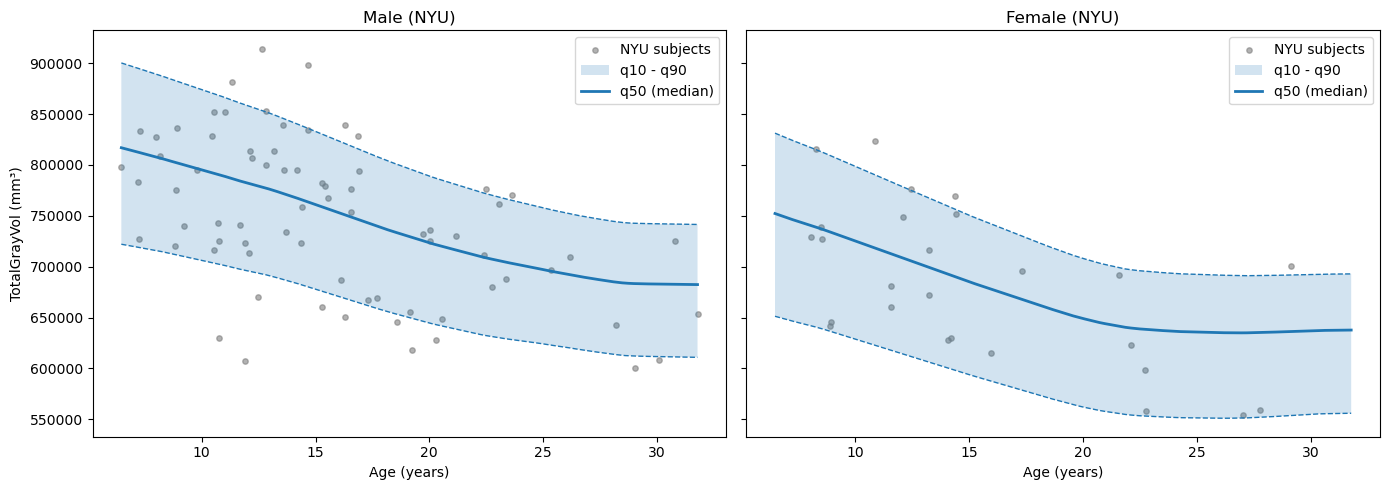

In [11]:
chart_site = 'NYU'
site_df = df[df['SITE_ID'] == chart_site]

# Age grid within the age range of the site
age_grid = np.linspace(site_df['AGE_AT_SCAN'].min(), site_df['AGE_AT_SCAN'].max(), 200)
age_grid_scaled = (age_grid - age_mean) / age_std

# Site columns: 1 for the chart site, 0 for the rest
site_values = np.array([1.0 if col == f'site_{chart_site}' else 0.0 for col in site_cols])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
model.eval()
for ax, (sex, label) in zip(axes, [(0, 'Male'), (1, 'Female')]):
    # Inputs: [Age, Sex, sites] for each age of the grid
    grid = np.column_stack([age_grid_scaled, np.full(len(age_grid), sex), np.tile(site_values, (len(age_grid), 1))])
    with torch.no_grad():
        preds = model(torch.tensor(grid, dtype=torch.float32).to(device)).cpu().numpy()

    # Back to mm³
    preds = preds * vol_std + vol_mean

    subset = site_df[site_df['SEX'] == sex]
    ax.scatter(subset['AGE_AT_SCAN'], subset['TotalGrayVol'], color='gray', s=15, alpha=0.6, label=f'{chart_site} subjects')
    ax.fill_between(age_grid, preds[:, 0], preds[:, 2], alpha=0.2, label='q10 - q90')
    ax.plot(age_grid, preds[:, 1], lw=2, label='q50 (median)')
    ax.plot(age_grid, preds[:, 0], lw=1, linestyle='--', color='C0')
    ax.plot(age_grid, preds[:, 2], lw=1, linestyle='--', color='C0')
    ax.set_title(f'{label} ({chart_site})')
    ax.set_xlabel('Age (years)')
    ax.legend()
axes[0].set_ylabel('TotalGrayVol (mm³)')
plt.tight_layout()
plt.show()

**Growth Charts per Site**

One panel per site, with the curves for males (blue) and females (orange) within the age range of each site.

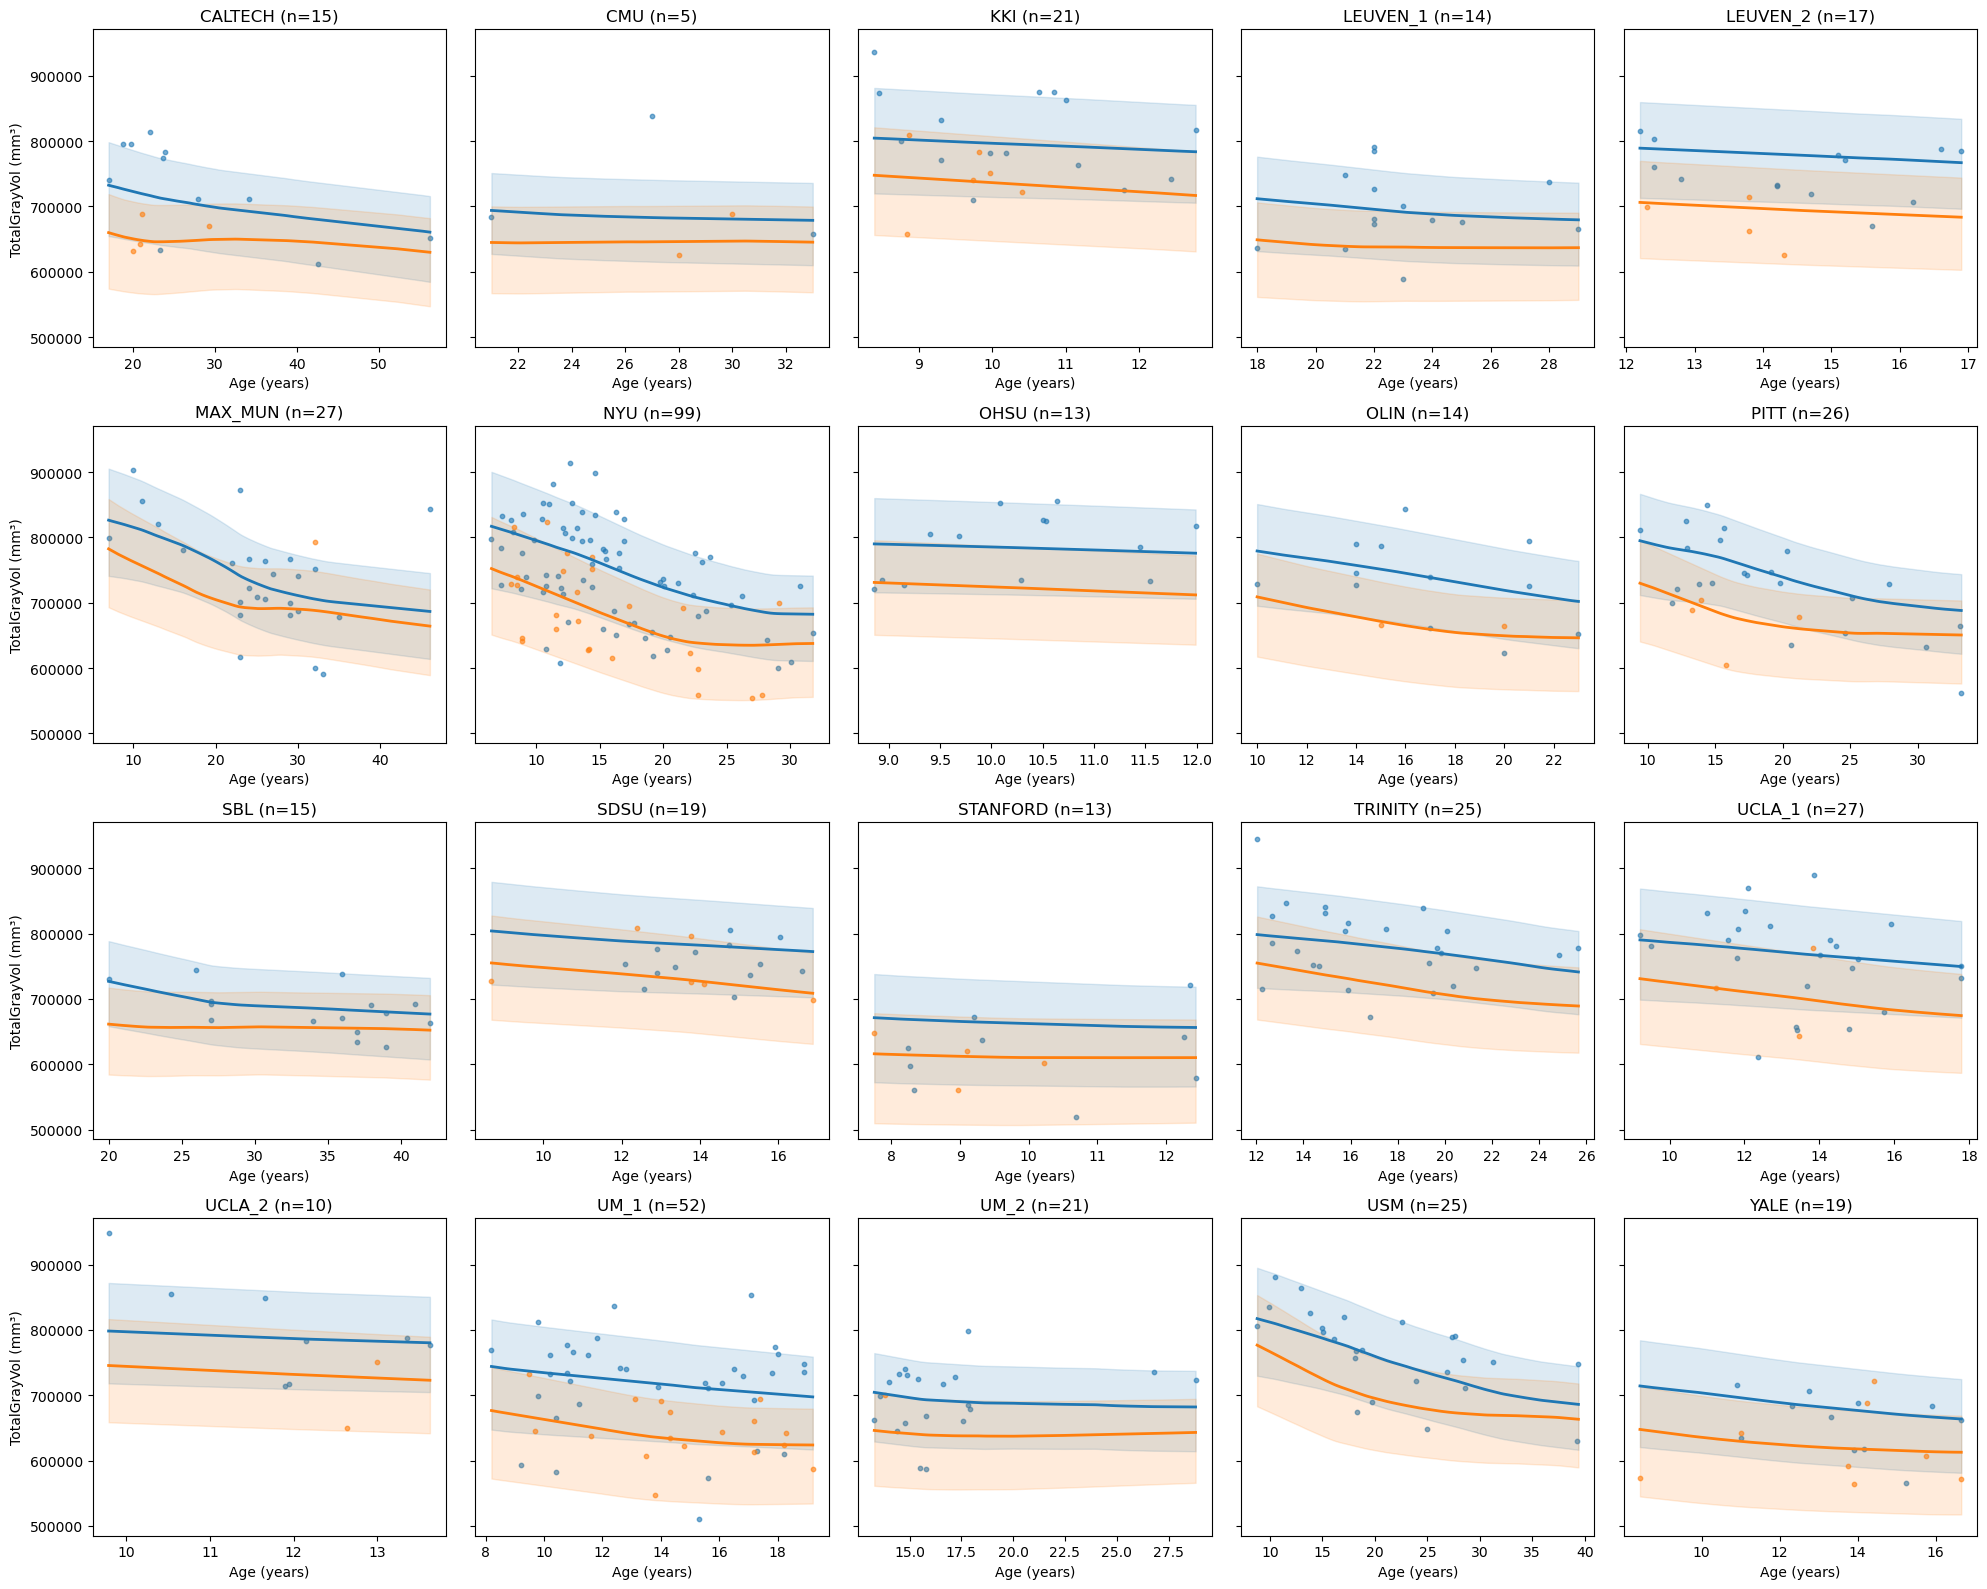

In [12]:
def predict_quantiles(ages, sex, site):
    """
    Predict q10, q50, q90 (mm³) for a list of ages, one sex and one site.

    ages: ages in years (array)
    sex: 0 = male, 1 = female (single value or array, same length as ages)
    site: SITE_ID, e.g. 'NYU'
    Returns: array [len(ages), 3] with columns q10, q50, q90
    """
    ages_scaled = (np.asarray(ages) - age_mean) / age_std
    site_values = np.array([1.0 if col == f'site_{site}' else 0.0 for col in site_cols])
    grid = np.column_stack([ages_scaled, np.broadcast_to(sex, ages_scaled.shape), np.tile(site_values, (len(ages_scaled), 1))])
    with torch.no_grad():
        preds = model(torch.tensor(grid, dtype=torch.float32).to(device)).cpu().numpy()
    return preds * vol_std + vol_mean

sites = sorted(df['SITE_ID'].unique())
n_cols = 5
n_rows = int(np.ceil(len(sites) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows), sharey=True)
model.eval()
for ax, site in zip(axes.flat, sites):
    site_df = df[df['SITE_ID'] == site]
    age_grid = np.linspace(site_df['AGE_AT_SCAN'].min(), site_df['AGE_AT_SCAN'].max(), 100)
    for sex, color in [(0, 'C0'), (1, 'C1')]:
        preds = predict_quantiles(age_grid, sex, site)
        subset = site_df[site_df['SEX'] == sex]
        ax.scatter(subset['AGE_AT_SCAN'], subset['TotalGrayVol'], color=color, s=10, alpha=0.6)
        ax.fill_between(age_grid, preds[:, 0], preds[:, 2], color=color, alpha=0.15)
        ax.plot(age_grid, preds[:, 1], color=color, lw=2)
    ax.set_title(f"{site} (n={len(site_df)})")
    ax.set_xlabel('Age (years)')
for ax in axes.flat[len(sites):]:
    ax.axis('off')
for row in axes:
    row[0].set_ylabel('TotalGrayVol (mm³)')
plt.tight_layout()
plt.show()

**Growth Charts, all Subjects (site adjusted)**

Site is an input of the model, so the curves are always drawn for one site: the reference site (`chart_site`, NYU). To plot the subjects of all sites together with these curves, each subject is moved to the reference site in two steps:

1. **Difference from the own site:** how far the subject is from the median of their own site (same age and sex). This removes the site offset.
$$d = \text{volume} - \hat{y}_{50}(\text{age}, \text{sex}, \text{own site})$$

2. **Back to volume units:** the difference is added to the median of the reference site, so it can be plotted next to the reference curves.
$$\text{adjusted volume} = \hat{y}_{50}(\text{age}, \text{sex}, \text{reference site}) + d$$

Example: a 12-year-old boy from Stanford with 650,000 mm³, where the median at Stanford is 660,000 and at NYU 780,000:
* $d = 650{,}000 - 660{,}000 = -10{,}000$ (10,000 below the typical value at his site)
* adjusted volume $= 780{,}000 - 10{,}000 = 770{,}000$

Each subject keeps the same distance from the median curve, only the reference curve changes. Subjects from the reference site do not change.

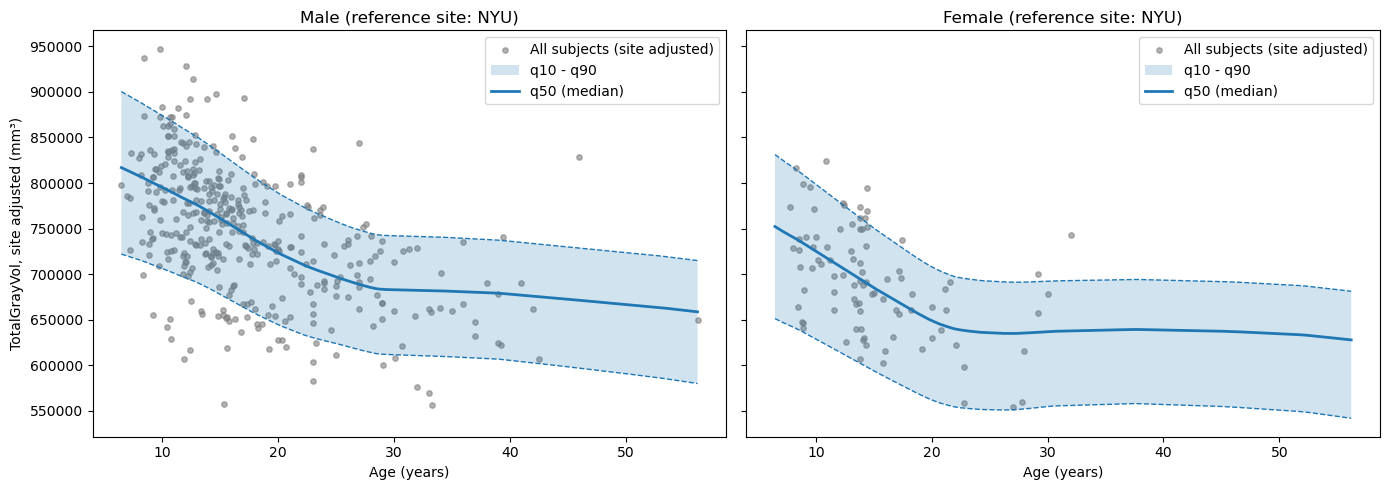

In [13]:
# Median at the own site and at the reference site, for each subject
own_median = np.array([predict_quantiles([age], sex, site)[0, 1]
                       for age, sex, site in zip(df['AGE_AT_SCAN'], df['SEX'], df['SITE_ID'])])
ref_median = predict_quantiles(df['AGE_AT_SCAN'].values, df['SEX'].values, chart_site)[:, 1]
df['TotalGrayVol_adjusted'] = df['TotalGrayVol'] - own_median + ref_median

age_grid = np.linspace(df['AGE_AT_SCAN'].min(), df['AGE_AT_SCAN'].max(), 200)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (sex, label) in zip(axes, [(0, 'Male'), (1, 'Female')]):
    preds = predict_quantiles(age_grid, sex, chart_site)
    subset = df[df['SEX'] == sex]
    ax.scatter(subset['AGE_AT_SCAN'], subset['TotalGrayVol_adjusted'], color='gray', s=15, alpha=0.6, label='All subjects (site adjusted)')
    ax.fill_between(age_grid, preds[:, 0], preds[:, 2], alpha=0.2, label='q10 - q90')
    ax.plot(age_grid, preds[:, 1], lw=2, label='q50 (median)')
    ax.plot(age_grid, preds[:, 0], lw=1, linestyle='--', color='C0')
    ax.plot(age_grid, preds[:, 2], lw=1, linestyle='--', color='C0')
    ax.set_title(f'{label} (reference site: {chart_site})')
    ax.set_xlabel('Age (years)')
    ax.legend()
axes[0].set_ylabel('TotalGrayVol, site adjusted (mm³)')
plt.tight_layout()
plt.show()